# **Box Plot 기본기 익히기**

matplotlib의 박스플롯을 학습하기 위한 실습입니다.


## **한글 폰트 설치**

In [1]:
# !pip install -q koreanize-matplotlib
# import koreanize_matplotlib
# import matplotlib.pyplot as plt
# import numpy as np
# import pandas as pd
# plt.rcParams['axes.unicode_minus'] = False
# %matplotlib inline

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import os

# 운영체제에 맞춰 한글 폰트 지정 (Visual Studio 환경이면 'nt'인 Windows로 작동)
if os.name == 'nt':
    plt.rcParams['font.family'] = 'Malgun Gothic'
else:
    plt.rcParams['font.family'] = 'AppleGothic'

# 축의 음수(-) 기호가 깨지는 현상 방지
plt.rcParams['axes.unicode_minus'] = False

## **박스플롯 기본 명령어**

| 명령어 / 옵션 | 의미 |
|---|---|
| `plt.boxplot(데이터)` | 데이터의 통계 요약을 박스 플롯으로 그리기 |
| `tick_labels=[...]` | 각 상자 아래에 표시될 이름 |
| `vert=False` | 가로로 그리기 (기본값 `True` = 세로) |
| `showmeans=True` | 평균값도 함께 표시 (기본값 `False`) |
| `plt.boxplot([데이터1, 데이터2, ...], tick_labels=[...])` | 여러 그룹을 나란히 비교 |


## **데이터 불러오기**

In [2]:
df = pd.read_csv("https://raw.githubusercontent.com/dukalee/datasets/refs/heads/main/student_scores.csv")
df.head()

,이름,공부시간,점수,출석률,성별
0,학생1,7,83,78,여
1,학생2,4,68,70,여
2,학생3,8,87,96,여
3,학생4,5,70,68,여
4,학생5,7,78,89,남


### **Q1. 기본 박스 플롯 그리기**

학생 40명 전체 점수를 가장 기본적인 형태의 박스 플롯으로 그려보자.

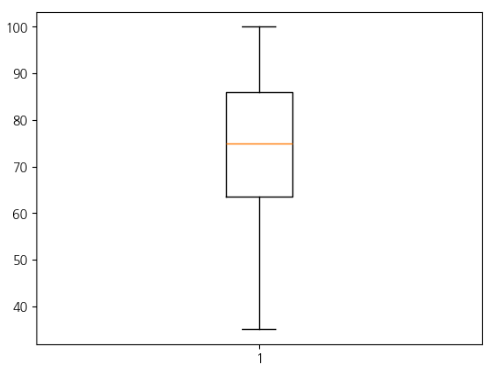


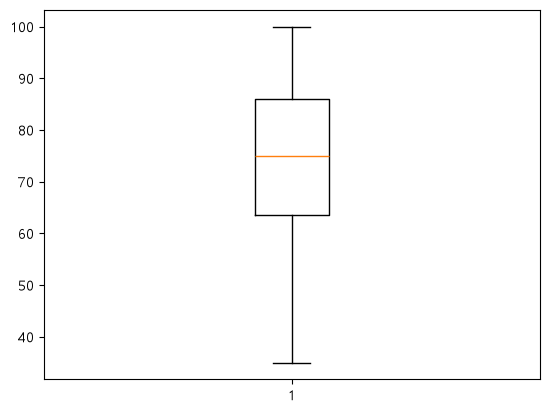

In [4]:
# code here
plt.boxplot(df["점수"])
plt.show()

### **Q2. 제목과 축 이름 붙이기**

- 제목 : '전체 점수 분포'
- X축 이름 : '학생 전체'
- Y축 이름 : '점수'


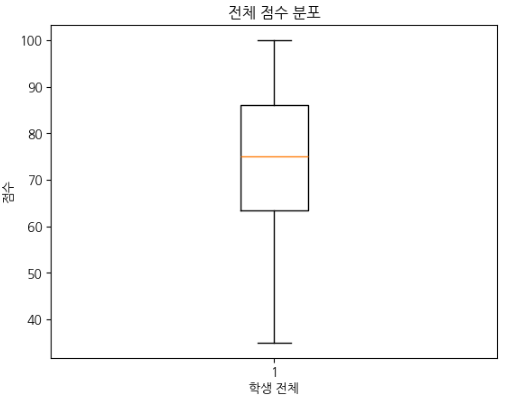

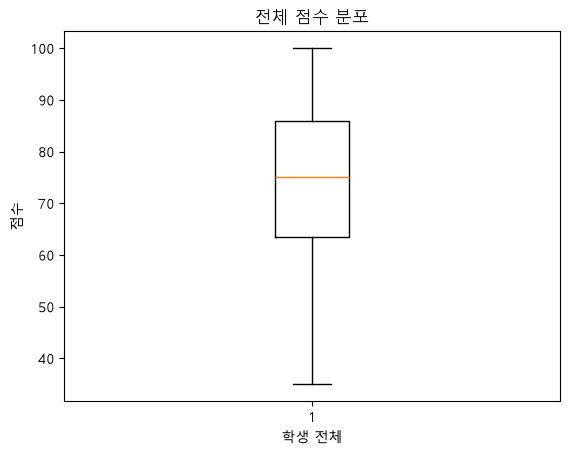

In [5]:
# code here
plt.title("전체 점수 분포")
plt.xlabel("학생 전체")
plt.ylabel("점수")
plt.boxplot(df["점수"])
plt.show()

### **Q3. 상자 이름 붙이기**

상자 아래에 '전체 점수' 라는 이름을 붙여보자.


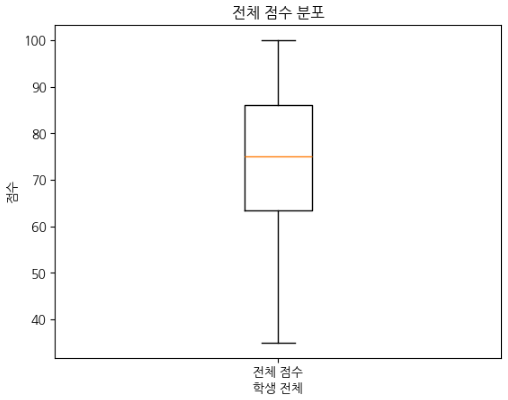

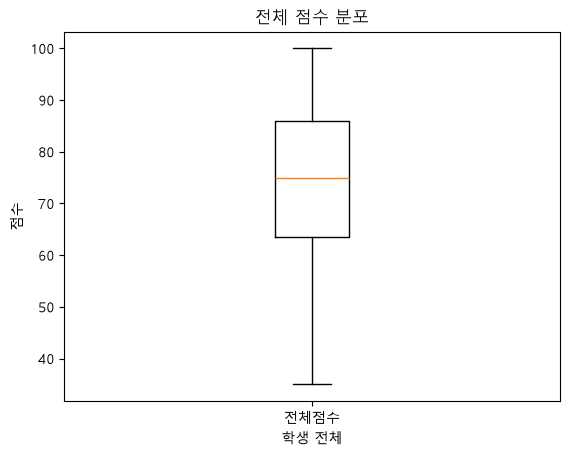

In [7]:
# code here
plt.title("전체 점수 분포")
plt.xlabel("학생 전체")
plt.ylabel("점수")
plt.boxplot(df["점수"], tick_labels=["전체점수"])
plt.show()

### **Q4. 가로로 그리기**

박스 플롯을 가로 방향으로 그려보자.


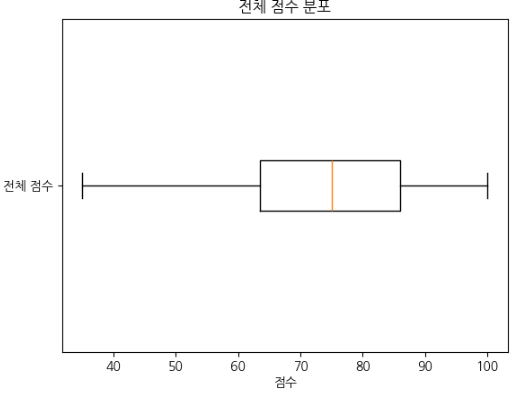

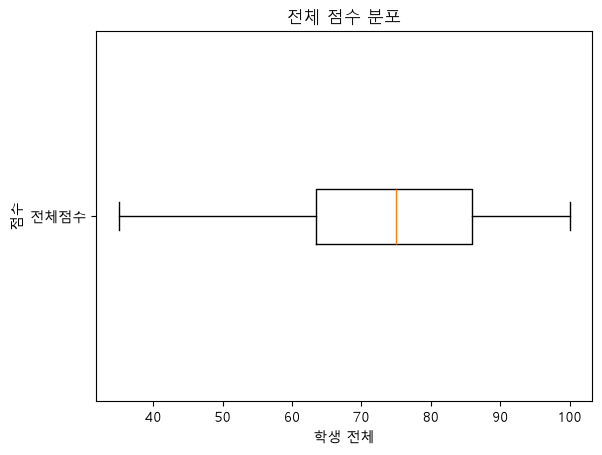

In [ ]:
# code here
# default option: vert = True
# 3.13 이후부터 orientation='horizontal'
plt.title("전체 점수 분포")
plt.xlabel("학생 전체")
plt.ylabel("점수")
plt.boxplot(df["점수"], tick_labels=["전체점수"], orientation='horizontal')
plt.show()

### **Q5. 평균값 표시하기**

중앙값과 아니라 평균값도 함께 표시해보자.
- 다시 세로 방향으로 그려보자.


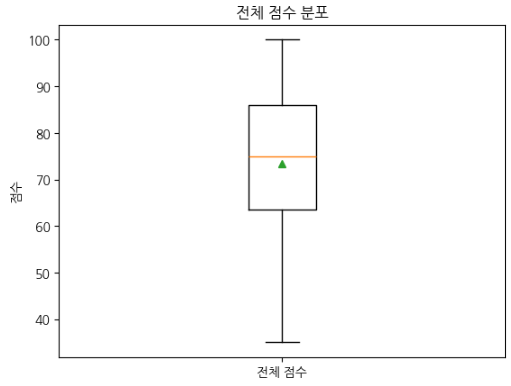

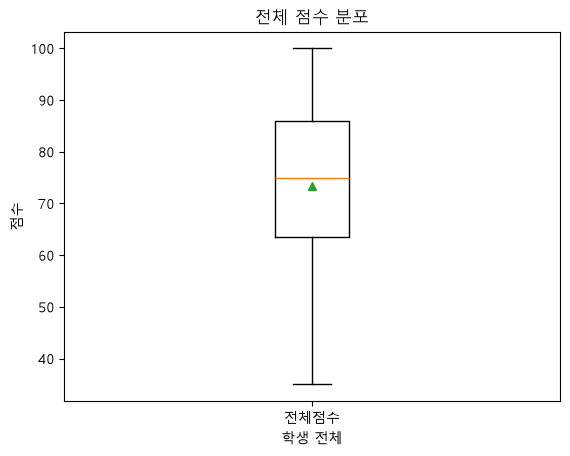

In [10]:
# code here
plt.title("전체 점수 분포")
plt.xlabel("학생 전체")
plt.ylabel("점수")
plt.boxplot(df["점수"], tick_labels=["전체점수"], orientation='vertical', showmeans=True)
plt.show()

### **Q6. 여러 그룹을 나란히 비교하기**

성별' 기준으로 남학생과 여학생의 점수를 나란히 비교해보자.


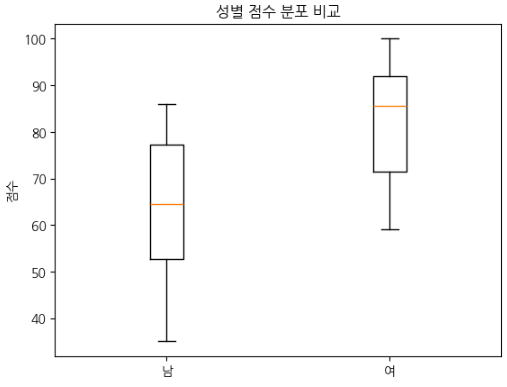

In [12]:
male_score = df[df["성별"] == "남"]["점수"]
female_score = df[df["성별"] == "여"]["점수"]

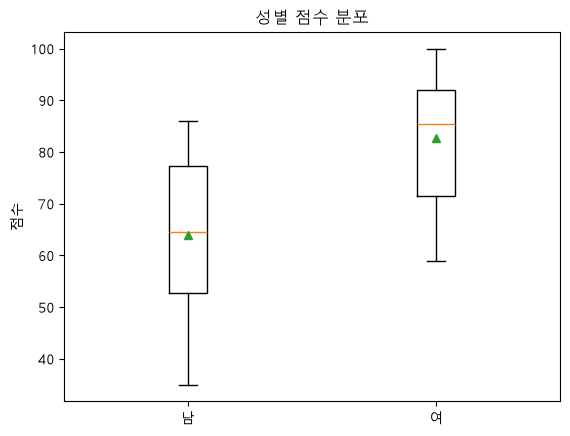

In [14]:
# code here
plt.title("성별 점수 분포")
plt.ylabel("점수")
plt.boxplot([male_score, female_score], orientation='vertical', tick_labels=["남", "여"] ,showmeans=True)
plt.show()

### **Q7. 새 열을 만들어서 그룹별로 비교하기**

- 점수가 70점 이상이면 1, 미만이면 0인 '합격여부' 열을 새로 만든다.
- 합격/불합격 두 그룹의 출석률을 박스 플롯으로 나란히 비교해보자.


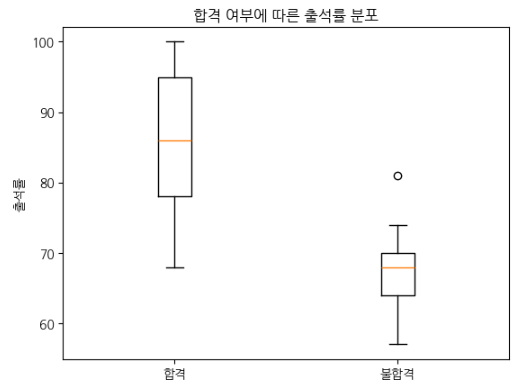

In [19]:
s = np.where(df["점수"] >= 70, 1, 0)
df["합격여부"] = s

passed_attend = df[df["합격여부"] == 1]["출석률"]
failed_attend = df[df["합격여부"] == 0]["출석률"]

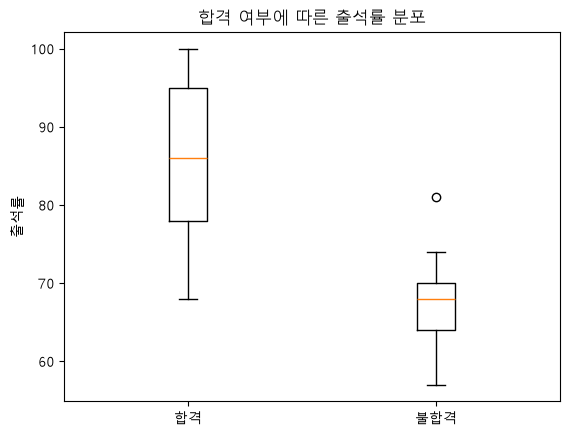

In [20]:
# code here
plt.title("합격 여부에 따른 출석률 분포")
plt.ylabel("출석률")
plt.boxplot([passed_attend, failed_attend], orientation='vertical', tick_labels=["합격", "불합격"])
plt.show()